# Non-linear static analysis with the arc-length methods

This example traces the snap-through of a hinged cylindrical roof under a central point load past its limit point, and compares the limit load with the literature.

With load control, the Newton-Raphson method fails at a limit point, where the tangent stiffness matrix becomes singular and the load must decrease to follow the path. The arc-length methods add the load factor $\lambda$ to the unknowns, with a constraint on the length $\Delta s$ of each step along the path in the space of $(\boldsymbol{c}, \lambda)$:

$$
\boldsymbol{F}_{int}(\boldsymbol{c}) - \lambda \boldsymbol{F}_{ext} = \boldsymbol{0}, \qquad \frac{\Delta \boldsymbol{c}^\top \Delta \boldsymbol{c}}{\boldsymbol{u}_{ref}^\top \boldsymbol{u}_{ref}} + \psi^2 \Delta\lambda^2 = \Delta s^2 ,
$$

where $\boldsymbol{u}_{ref}$ is the linear solution for $\lambda = 1$, which makes $\Delta s$ independent of the units of the model, and $\psi$ is a constant. Riks's method iterates on the plane normal to the predictor of each step, while Crisfield's method keeps the spherical constraint. Both are implemented in [structsolve](https://github.com/saullocastro/structsolve), selected with `NL_method='arc_length_riks'` or `NL_method='arc_length_crisfield'` of `structsolve.Analysis`. The methods `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of the `Shell` object are passed directly to `structsolve.Analysis`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import Analysis
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## The hinged roof of Sabir and Lock

The benchmark of Sabir and Lock (1972), as given by Sze et al. (2004), Section 3.8 and Fig. 9a, is a shallow cylindrical panel of radius $R = 2540$ mm and length $2L = 508$ mm along the axis, with free curved edges. Its straight edges are $R\theta$ apart, $\theta = 0.2$ rad, and hinged: $u = v = w = 0$ with the rotations free. The panel is isotropic, $E = 3102.75$ MPa, $\nu = 0.3$, $h = 12.7$ mm, and is loaded by a point force at its center. Units are N, mm and MPa. The model is `cylshell_clpt_donnell` with $6 \times 6$ terms and $12 \times 12$ integration points.

In [2]:
s = Shell(model='cylshell_clpt_donnell', a=508., b=2540.*0.2, r=2540.,
          stack=[0.], plyt=12.7, laminaprop=(3102.75, 0.3), m=6, n=6)
s.nx = 2*s.m
s.ny = 2*s.n
for edge in ('x1', 'x2', 'y1', 'y2'):
    for field in 'uvw':
        setattr(s, edge + field, 1.)
        setattr(s, edge + field + 'r', 1.)
for edge in ('y1', 'y2'):  # hinged straight edges
    for field in 'uvw':
        setattr(s, edge + field, 0.)

## Riks method

The reference load $P_{ref} = 4000$ N is larger than the limit load, so the analysis must pass the limit point and the snap-through before reaching $\lambda = 1$. `initialInc` is the first increment of $\lambda$. `maxArcLength` and `maxInc` limit the step, so that the path is sampled finely enough to show the limit point and the minimum load after it.

In [3]:
Pref = 4000.
s.add_point_load(s.a/2., s.b/2., 0., 0., -Pref, cte=False)

an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
an.NL_method = 'arc_length_riks'
an.initialInc = 0.05
an.maxArcLength = 50.
an.maxInc = 0.02
increments, cs = an.static(NLgeom=True, silent=True)

lbds = np.asarray(increments)
wc = np.array([s.uvw(c=c, gridx=3, gridy=3)[1]['w'][1, 1] for c in cs])
for lbd, w in zip(lbds, wc):
    print('  load %7.1f N, center deflection %8.4f mm' % (lbd*Pref, w))

  load   199.4 N, center deflection  -0.4044 mm
  load   397.4 N, center deflection  -0.8280 mm
  load   594.0 N, center deflection  -1.2737 mm
  load   789.0 N, center deflection  -1.7449 mm
  load   982.3 N, center deflection  -2.2459 mm
  load  1173.6 N, center deflection  -2.7827 mm
  load  1362.7 N, center deflection  -3.3637 mm
  load  1549.0 N, center deflection  -4.0008 mm
  load  1732.0 N, center deflection  -4.7132 mm
  load  1910.3 N, center deflection  -5.5348 mm
  load  2081.4 N, center deflection  -6.5368 mm
  load  2235.1 N, center deflection  -7.9372 mm
  load  2234.4 N, center deflection -10.6436 mm
  load  2101.4 N, center deflection -11.7653 mm
  load  1945.9 N, center deflection -12.5818 mm
  load  1790.3 N, center deflection -13.2084 mm
  load  1635.8 N, center deflection -13.7363 mm
  load  1482.6 N, center deflection -14.2095 mm
  load  1330.9 N, center deflection -14.6558 mm
  load  1180.6 N, center deflection -15.0973 mm
  load  1032.0 N, center deflection -15.

## Equilibrium and the path

Every converged step is in equilibrium: the residual $\boldsymbol{F}_{int} - \lambda \boldsymbol{F}_{ext}$ is small relative to the forces. The limit point is the last converged step before the first decrease of the load.

In [4]:
fext = s.calc_fext()
residuals = [np.linalg.norm(s.calc_fint(c=c) - lbd*fext)
             / max(np.linalg.norm(lbd*fext), np.linalg.norm(s.calc_fint(c=c)))
             for lbd, c in zip(lbds, cs)]
print('largest relative residual of the converged steps: %.2e'
      % max(residuals))
ilim = np.argmax(np.diff(lbds) < 0)
imin = ilim + np.argmin(lbds[ilim:])
print('limit point: %.1f N at w = %.3f mm; minimum after it: %.1f N at '
      'w = %.3f mm; final: %.1f N at w = %.3f mm'
      % (lbds[ilim]*Pref, wc[ilim], lbds[imin]*Pref, wc[imin],
         lbds[-1]*Pref, wc[-1]))

largest relative residual of the converged steps: 9.04e-09
limit point: 2235.1 N at w = -7.937 mm; minimum after it: 499.8 N at w = -18.547 mm; final: 4000.0 N at w = -29.103 mm


The load-deflection path, with the first maximum of the load of Sze et al. (2004), Table 9a ($P/P_{max} = 0.7421$ with $P_{max} = 3000$ N at $-W_C = 11.293$ mm, ABAQUS S4R elements):

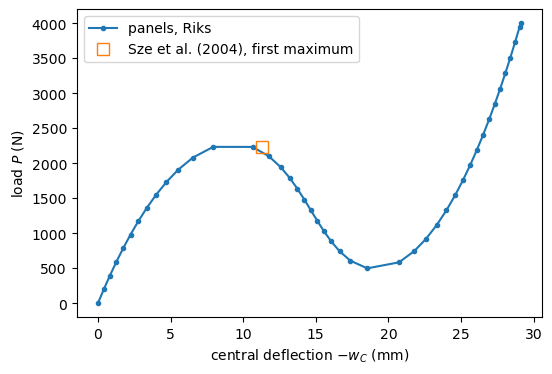

In [5]:
SZE_PLIM, SZE_W = 0.7421*3000., 11.293
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(-np.r_[0, wc], np.r_[0, lbds]*Pref, 'o-', ms=3, label='panels, Riks')
ax.plot(SZE_W, SZE_PLIM, 's', mfc='none', ms=9,
        label='Sze et al. (2004), first maximum')
ax.set_xlabel('central deflection $-w_C$ (mm)')
ax.set_ylabel('load $P$ (N)')
ax.legend()
plt.show()

## Results

The limit load is 0.4% above that of Sze et al. (2004). The deflection at the largest converged load is not compared: the load is nearly constant around the limit point, so that deflection depends on where the arc length samples the path. The final deflection at $P = 4000$ N is compared with the regression value of the panels unit test `tests/tests_shell/test_nonlinear_riks.py`, checked there within 2%.

In [6]:
results_table([
    ('limit load (N)', lbds[ilim]*Pref, SZE_PLIM,
     'Sze et al. (2004), Table 9a'),
    ('load factor at the end', lbds[-1], 1., 'end of the analysis'),
    ('central deflection at $P = 4000$ N (mm)', wc[-1], -29.1,
     'regression value, `test_nonlinear_riks.py`'),
])

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| limit load (N) | 2235.06 | 2226.3 | +3.94e-03 | Sze et al. (2004), Table 9a |
| load factor at the end | 1 | 1 | +0.00e+00 | end of the analysis |
| central deflection at $P = 4000$ N (mm) | -29.1026 | -29.1 | -8.78e-05 | regression value, `test_nonlinear_riks.py` |

The same analysis runs with the Crisfield method by setting `an.NL_method = 'arc_length_crisfield'`.

## References

1. A. B. Sabir and A. C. Lock, "The application of finite elements to the large deflection geometrically nonlinear behaviour of cylindrical shells". In: C. A. Brebbia and H. Tottenham (eds), Variational Methods in Engineering, Southampton University Press, Southampton, UK, 1972, pp. 7/54-7/65 (as cited by Sze et al., 2004).
2. K. Y. Sze, X. H. Liu and S. H. Lo, "Popular benchmark problems for geometric nonlinear analysis of shells". Finite Elements in Analysis and Design, 40:1551-1569, 2004. https://doi.org/10.1016/j.finel.2003.11.001.